In [1]:
import torch
import torch.optim as optim
import pandas as pd
from google.colab import drive
drive.mount('/content/drive')
import matplotlib.pyplot as plt

Mounted at /content/drive


In [2]:
t_c = [0.5, 14.0, 15.0, 28.0, 11.0, 8.0, 3.0, -4.0, 6.0, 13.0, 21.0]
t_u = [35.7, 55.9, 58.2, 81.9, 56.3, 48.9, 33.9, 21.8, 48.4, 60.4, 68.4]
t_c = torch.tensor(t_c)
t_u = torch.tensor(t_u)

t_un = 0.1 * t_u

In [3]:
def model_linear(t_u, w, b):
    return w * t_u + b

def model_nonlinear(t_u, w2, w1, b):
    return w2 * t_u ** 2 + w1 * t_u + b

def loss_fn(t_p, t_c):
    squared_diffs = (t_p - t_c)**2
    return squared_diffs.mean()

In [4]:
def training_loop(n_epochs, optimizer, params, t_u, t_c, model):
    losses = []
    for epoch in range(1, n_epochs + 1):
        t_p = model(t_u, *params)
        loss = loss_fn(t_p, t_c)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        if epoch % 500 == 0:
            print('Epoch %d, Loss %f' % (epoch, loss.item()))
            losses.append(loss.item())

    return params, losses

In [5]:
params_linear = torch.tensor([1.0, 0.0], requires_grad=True)
optimizer = optim.SGD([params_linear], lr=1e-2)

params_linear, losses_linear = training_loop(
    n_epochs=5000,
    optimizer=optimizer,
    params=params_linear,
    t_u=t_un,
    t_c=t_c,
    model=model_linear)
print(params_linear)

Epoch 500, Loss 7.860120
Epoch 1000, Loss 3.828538
Epoch 1500, Loss 3.092191
Epoch 2000, Loss 2.957698
Epoch 2500, Loss 2.933134
Epoch 3000, Loss 2.928648
Epoch 3500, Loss 2.927830
Epoch 4000, Loss 2.927679
Epoch 4500, Loss 2.927652
Epoch 5000, Loss 2.927647
tensor([  5.3671, -17.3012], requires_grad=True)


In [6]:
learning_rates = [1e-1, 1e-2, 1e-3, 1e-4]
results_nl = {}

for lr in learning_rates:
    print(f'--- learning rate = {lr} ---')
    params = torch.tensor([1.0, 1.0, 0.0], requires_grad=True)
    optimizer = optim.SGD([params], lr=lr)
    params, losses = training_loop(5000, optimizer, params, t_un, t_c, model_nonlinear)
    results_nl[lr] = (params.detach().clone(), losses)
    print(params)

--- learning rate = 0.1 ---
Epoch 500, Loss nan
Epoch 1000, Loss nan
Epoch 1500, Loss nan
Epoch 2000, Loss nan
Epoch 2500, Loss nan
Epoch 3000, Loss nan
Epoch 3500, Loss nan
Epoch 4000, Loss nan
Epoch 4500, Loss nan
Epoch 5000, Loss nan
tensor([nan, nan, nan], requires_grad=True)
--- learning rate = 0.01 ---
Epoch 500, Loss nan
Epoch 1000, Loss nan
Epoch 1500, Loss nan
Epoch 2000, Loss nan
Epoch 2500, Loss nan
Epoch 3000, Loss nan
Epoch 3500, Loss nan
Epoch 4000, Loss nan
Epoch 4500, Loss nan
Epoch 5000, Loss nan
tensor([nan, nan, nan], requires_grad=True)
--- learning rate = 0.001 ---
Epoch 500, Loss nan
Epoch 1000, Loss nan
Epoch 1500, Loss nan
Epoch 2000, Loss nan
Epoch 2500, Loss nan
Epoch 3000, Loss nan
Epoch 3500, Loss nan
Epoch 4000, Loss nan
Epoch 4500, Loss nan
Epoch 5000, Loss nan
tensor([nan, nan, nan], requires_grad=True)
--- learning rate = 0.0001 ---
Epoch 500, Loss 10.708596
Epoch 1000, Loss 8.642083
Epoch 1500, Loss 7.171005
Epoch 2000, Loss 6.123478
Epoch 2500, Loss 5.

In [7]:
epochs_logged = list(range(500, 5001, 500))
loss_table = pd.DataFrame({f'lr={lr}': results_nl[lr][1] for lr in learning_rates},
                          index=epochs_logged)
loss_table.index.name = 'epoch'
loss_table

,lr=0.1,lr=0.01,lr=0.001,lr=0.0001
epoch,,,,
500,NaN,NaN,NaN,10.708596
1000,NaN,NaN,NaN,8.642083
1500,NaN,NaN,NaN,7.171005
2000,NaN,NaN,NaN,6.123478
2500,NaN,NaN,NaN,5.377227
3000,NaN,NaN,NaN,4.845286
3500,NaN,NaN,NaN,4.465788
4000,NaN,NaN,NaN,4.194724
4500,NaN,NaN,NaN,4.000802


In [8]:
finite_runs = {lr: res for lr, res in results_nl.items() if res[1][-1] == res[1][-1]}
best_lr = min(finite_runs, key=lambda lr: finite_runs[lr][1][-1])
params_nl, losses_nl = results_nl[best_lr]

print('Best non-linear learning rate:', best_lr)
print('Non-linear params [w2, w1, b]:', params_nl)
print('Non-linear final loss: %.4f' % losses_nl[-1])
print('Linear params [w, b]:        ', params_linear.detach())
print('Linear final loss:     %.4f' % losses_linear[-1])

Best non-linear learning rate: 0.0001
Non-linear params [w2, w1, b]: tensor([ 0.5570, -0.8881, -0.8753])
Non-linear final loss: 3.8617
Linear params [w, b]:         tensor([  5.3671, -17.3012])
Linear final loss:     2.9276


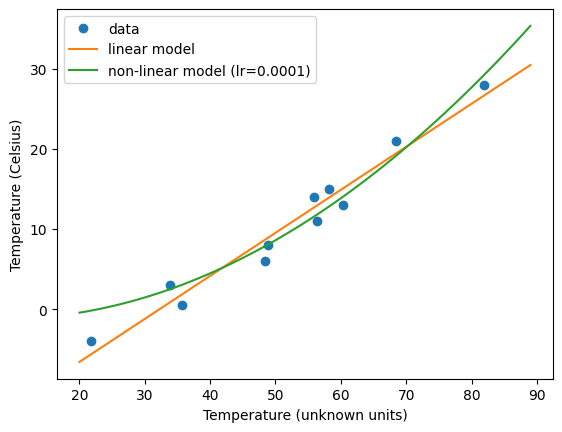

In [9]:
t_range = torch.arange(20., 90.).unsqueeze(1)

fig = plt.figure(dpi=100)
plt.xlabel('Temperature (unknown units)')
plt.ylabel('Temperature (Celsius)')
plt.plot(t_u.numpy(), t_c.numpy(), 'o', label='data')
plt.plot(t_range.numpy(), model_linear(0.1 * t_range, *params_linear).detach().numpy(),
         label='linear model')
plt.plot(t_range.numpy(), model_nonlinear(0.1 * t_range, *params_nl).detach().numpy(),
         label=f'non-linear model (lr={best_lr})')
plt.legend()
plt.show()

In [10]:
housing_file_path = '/content/drive/My Drive/IntroToML/Housing.csv'
df = pd.read_csv(housing_file_path)

binary_cols = ['mainroad', 'guestroom', 'basement', 'hotwaterheating',
               'airconditioning', 'prefarea']
df[binary_cols] = df[binary_cols].apply(lambda col: col.map({'yes': 1, 'no': 0}))

df = pd.get_dummies(df, columns=['furnishingstatus'], drop_first=True, dtype=int)

price = torch.tensor(df['price'].values, dtype=torch.float32)

torch.manual_seed(42)
n_samples = len(df)
n_val = int(0.2 * n_samples)

shuffled_indices = torch.randperm(n_samples)
train_indices = shuffled_indices[:-n_val]
val_indices = shuffled_indices[-n_val:]

print(f'Training rows: {len(train_indices)}, Validation rows: {len(val_indices)}')

Training rows: 436, Validation rows: 109


In [11]:
def prepare_data(features):
    X = torch.tensor(df[features].values, dtype=torch.float32)
    train_X, val_X = X[train_indices], X[val_indices]

    mean, std = train_X.mean(dim=0), train_X.std(dim=0)
    train_X = (train_X - mean) / std
    val_X = (val_X - mean) / std
    return train_X, val_X, price[train_indices], price[val_indices]

In [12]:
def model_housing(X, params):
    return X @ params[:-1] + params[-1]

def training_loop_val(n_epochs, optimizer, params, train_X, val_X, train_y, val_y):
    log = []
    for epoch in range(1, n_epochs + 1):
        train_p = model_housing(train_X, params)
        train_loss = loss_fn(train_p, train_y)

        with torch.no_grad():
            val_p = model_housing(val_X, params)
            val_loss = loss_fn(val_p, val_y)
            val_r2 = 1 - ((val_p - val_y)**2).sum() / ((val_y - val_y.mean())**2).sum()

        optimizer.zero_grad()
        train_loss.backward()
        optimizer.step()

        if epoch % 500 == 0:
            log.append((epoch, train_loss.item(), val_loss.item(), val_r2.item()))

    return params, pd.DataFrame(log, columns=['epoch', 'train_loss', 'val_loss', 'val_R2']).set_index('epoch')

In [13]:
def run_experiment(features):
    train_X, val_X, train_y, val_y = prepare_data(features)
    results = {}
    for lr in learning_rates:
        params = torch.zeros(len(features) + 1, requires_grad=True)
        optimizer = optim.SGD([params], lr=lr)
        params, log = training_loop_val(5000, optimizer, params, train_X, val_X, train_y, val_y)
        results[lr] = (params.detach().clone(), log)
        print(f'--- learning rate = {lr} ---')
        print(log.to_string(float_format=lambda v: f'{v:.4e}' if abs(v) > 100 else f'{v:.4f}'))
        print()
    return results

def report_best(results, features):
    best_lr = min(results, key=lambda lr: results[lr][1]['val_loss'].iloc[-1])
    params, log = results[best_lr]
    print('Best learning rate (lowest final validation loss):', best_lr)
    print('Final train loss: %.4e' % log['train_loss'].iloc[-1])
    print('Final val loss:   %.4e' % log['val_loss'].iloc[-1])
    print('Final val R2:     %.4f' % log['val_R2'].iloc[-1])
    print()
    print(pd.Series(params.numpy(), index=features + ['bias']))

In [14]:
features_a = ['area', 'bedrooms', 'bathrooms', 'stories', 'parking']
results_2 = run_experiment(features_a)

--- learning rate = 0.1 ---
       train_loss   val_loss  val_R2
epoch                               
500    1.5899e+12 1.3267e+12  0.5298
1000   1.5899e+12 1.3267e+12  0.5298
1500   1.5899e+12 1.3267e+12  0.5298
2000   1.5899e+12 1.3267e+12  0.5298
2500   1.5899e+12 1.3267e+12  0.5298
3000   1.5899e+12 1.3267e+12  0.5298
3500   1.5899e+12 1.3267e+12  0.5298
4000   1.5899e+12 1.3267e+12  0.5298
4500   1.5899e+12 1.3267e+12  0.5298
5000   1.5899e+12 1.3267e+12  0.5298

--- learning rate = 0.01 ---
       train_loss   val_loss  val_R2
epoch                               
500    1.5899e+12 1.3262e+12  0.5299
1000   1.5899e+12 1.3267e+12  0.5298
1500   1.5899e+12 1.3267e+12  0.5298
2000   1.5899e+12 1.3267e+12  0.5298
2500   1.5899e+12 1.3267e+12  0.5298
3000   1.5899e+12 1.3267e+12  0.5298
3500   1.5899e+12 1.3267e+12  0.5298
4000   1.5899e+12 1.3267e+12  0.5298
4500   1.5899e+12 1.3267e+12  0.5298
5000   1.5899e+12 1.3267e+12  0.5298

--- learning rate = 0.001 ---
       train_loss   val

In [15]:
report_best(results_2, features_a)

Best learning rate (lowest final validation loss): 0.001
Final train loss: 1.5899e+12
Final val loss:   1.3262e+12
Final val R2:     0.5299

area         7.546734e+05
bedrooms     5.771744e+04
bathrooms    5.761571e+05
stories      4.745994e+05
parking      3.353070e+05
bias         4.758596e+06
dtype: float32


In [16]:
features_all = ['area', 'bedrooms', 'bathrooms', 'stories', 'mainroad', 'guestroom',
                'basement', 'hotwaterheating', 'airconditioning', 'parking', 'prefarea',
                'furnishingstatus_semi-furnished', 'furnishingstatus_unfurnished']

results_3 = run_experiment(features_all)

--- learning rate = 0.1 ---
       train_loss   val_loss  val_R2
epoch                               
500    1.1693e+12 9.2672e+11  0.6715
1000   1.1693e+12 9.2672e+11  0.6715
1500   1.1693e+12 9.2672e+11  0.6715
2000   1.1693e+12 9.2672e+11  0.6715
2500   1.1693e+12 9.2672e+11  0.6715
3000   1.1693e+12 9.2672e+11  0.6715
3500   1.1693e+12 9.2672e+11  0.6715
4000   1.1693e+12 9.2672e+11  0.6715
4500   1.1693e+12 9.2672e+11  0.6715
5000   1.1693e+12 9.2672e+11  0.6715

--- learning rate = 0.01 ---
       train_loss   val_loss  val_R2
epoch                               
500    1.1693e+12 9.2479e+11  0.6722
1000   1.1693e+12 9.2668e+11  0.6715
1500   1.1693e+12 9.2672e+11  0.6715
2000   1.1693e+12 9.2672e+11  0.6715
2500   1.1693e+12 9.2672e+11  0.6715
3000   1.1693e+12 9.2672e+11  0.6715
3500   1.1693e+12 9.2672e+11  0.6715
4000   1.1693e+12 9.2672e+11  0.6715
4500   1.1693e+12 9.2672e+11  0.6715
5000   1.1693e+12 9.2672e+11  0.6715

--- learning rate = 0.001 ---
       train_loss   val

In [17]:
report_best(results_3, features_all)

Best learning rate (lowest final validation loss): 0.001
Final train loss: 1.1693e+12
Final val loss:   9.2478e+11
Final val R2:     0.6722

area                               5.597791e+05
bedrooms                           3.281576e+04
bathrooms                          4.958628e+05
stories                            4.216281e+05
mainroad                           1.141088e+05
guestroom                          9.601219e+04
basement                           1.761391e+05
hotwaterheating                    1.275874e+05
airconditioning                    3.769896e+05
parking                            2.553941e+05
prefarea                           3.122747e+05
furnishingstatus_semi-furnished   -5.825058e+04
furnishingstatus_unfurnished      -2.404047e+05
bias                               4.758596e+06
dtype: float32
